# Guía 3: características, protocolo y prueba temporal
**Benjamin Guzman Miranda** · Registro sEMG crudo del participante 1

Las características describen ventanas del registro, sin estimar fuerza, diagnosticar ni demostrar clasificación. Se usa el mismo original del notebook EDA y se mantienen sus banderas de calidad.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / "src/procesamiento.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
from procesamiento import FS, load_data, eda, characteristics, temporal_and_validation
print("Directorio del proyecto:", ROOT.name)


Directorio del proyecto: PDSB_Guia3


## Definiciones y parámetros
Por ventana no solapada de 2 s (4.000 muestras) se define y[n]=x[n]-media(x).

RMS AC = sqrt(mean(y²)), en mV. MAV AC = mean(|y|), en mV. Se elimina el nivel medio local para describir fluctuaciones, sin tratar esta resta como un filtro completo ni una calibración.

La PSD unilateral de Welch usa fs=2.000 Hz, Hann periódica, subsegmentos de 2.000 muestras (1 s), solapamiento de 1.000 muestras (50%), detrend constante por subsegmento y escala density (mV²/Hz). El espaciado de bins es 1 Hz. El dominio de integración es 0-1.000 Hz, sin afirmar que toda esa potencia sea muscular. La mediana espectral divide a la mitad la integral de PSD; se interpola la integral acumulada calculada por trapecios. La frecuencia media es integral(f·PSD)/integral(PSD), en Hz. La PSD tiene variabilidad de estimación y puede incluir interferencias.

Se calculan 1.280 filas y se resumen 1.277 que superan los controles definidos. Las tres ventanas marcadas del canal 1 permanecen en la tabla. La frecuencia de una señal completamente constante tras centrarla queda indefinida (NaN); su potencia es cero.

Ventanas totales/aceptadas: 1280 1277
Ventanas marcadas (se conservan, se omiten del resumen de actividad):
   canal  inicio_s  fin_s_exclusivo  muestras  rms_ac_mV  mav_ac_mV  frecuencia_mediana_Hz  frecuencia_media_Hz  potencia_psd_mV2  muestras_marcadas  valida_calidad
Canal_1      14.0             16.0      4000   0.323116   0.232981             110.922643           127.896615          0.127242                  3           False
Canal_1     532.0            534.0      4000   0.172213   0.159500               1.134722             6.229704          0.002581               1395           False
Canal_1     534.0            536.0      4000   0.000000   0.000000                    NaN                  NaN          0.000000               4000           False
Comparación CH4, ciclo 1:
   canal  inicio_s  fin_s_exclusivo  muestras  rms_ac_mV  mav_ac_mV  frecuencia_mediana_Hz  frecuencia_media_Hz  potencia_psd_mV2  muestras_marcadas  valida_calidad  ciclo  gesto_id condicion_nominal
Canal_4  

,canal,inicio_s,fin_s_exclusivo,muestras,rms_ac_mV,mav_ac_mV,frecuencia_mediana_Hz,frecuencia_media_Hz,potencia_psd_mV2,muestras_marcadas,valida_calidad
0,Canal_1,0.0,2.0,4000,0.083622,0.062150,50.703931,63.001968,0.004627,0,True
1,Canal_1,2.0,4.0,4000,0.048331,0.036716,73.886097,86.458047,0.002018,0,True
2,Canal_1,4.0,6.0,4000,0.043071,0.033405,75.204698,87.382602,0.001650,0,True
3,Canal_1,6.0,8.0,4000,0.046687,0.034988,75.670070,85.444156,0.002175,0,True
4,Canal_1,8.0,10.0,4000,0.043503,0.033517,56.205445,79.121805,0.001802,0,True


,canal,inicio_s,fin_s_exclusivo,muestras,rms_ac_mV,mav_ac_mV,frecuencia_mediana_Hz,frecuencia_media_Hz,potencia_psd_mV2,muestras_marcadas,valida_calidad
7,Canal_1,14.0,16.0,4000,0.323116,0.232981,110.922643,127.896615,0.127242,3,False
266,Canal_1,532.0,534.0,4000,0.172213,0.159500,1.134722,6.229704,0.002581,1395,False
267,Canal_1,534.0,536.0,4000,0.000000,0.000000,NaN,NaN,0.000000,4000,False


,canal,inicio_s,fin_s_exclusivo,muestras,rms_ac_mV,mav_ac_mV,frecuencia_mediana_Hz,frecuencia_media_Hz,potencia_psd_mV2,muestras_marcadas,valida_calidad,ciclo,gesto_id,condicion_nominal
0,Canal_4,6.0,8.0,4000,0.006439,0.004387,109.328003,122.137358,0.000042,0,True,1,0,Reposo
1,Canal_4,56.0,58.0,4000,0.006524,0.004889,130.412277,149.688651,0.000038,0,True,1,5,Agarre


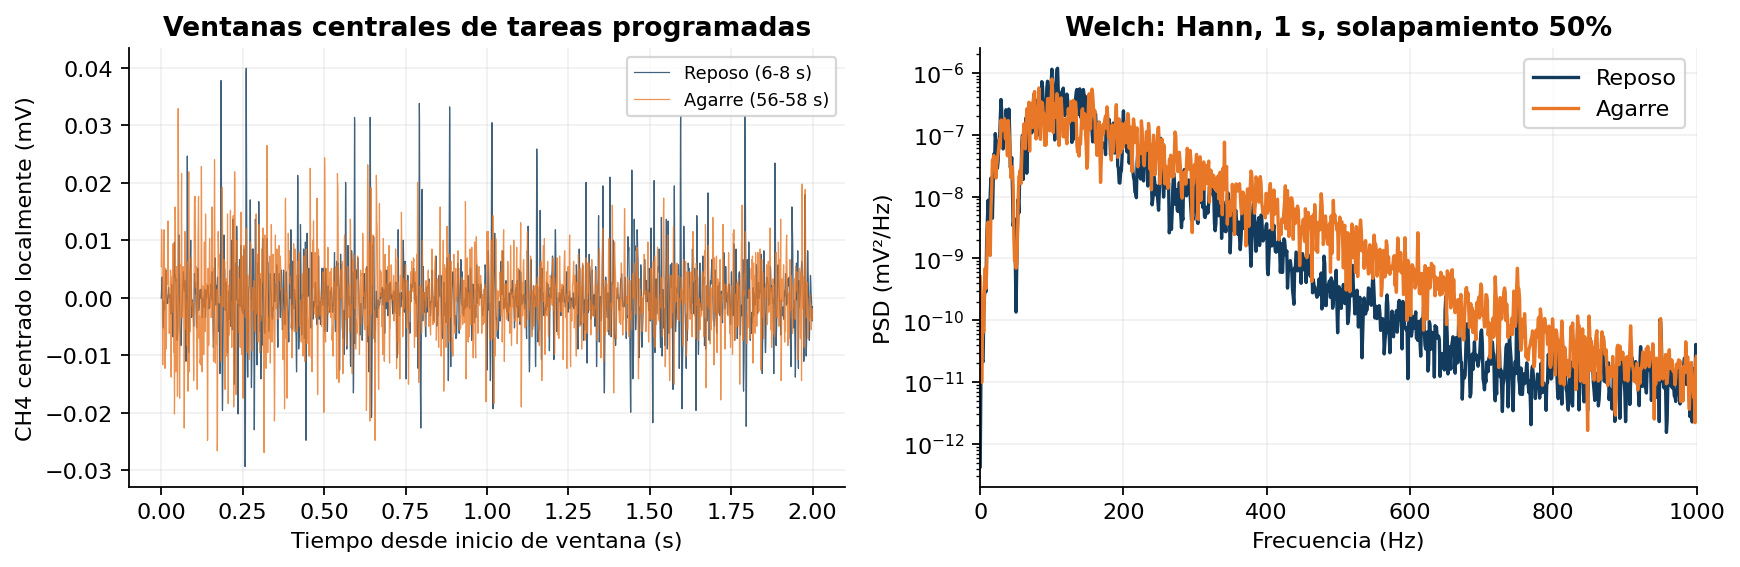

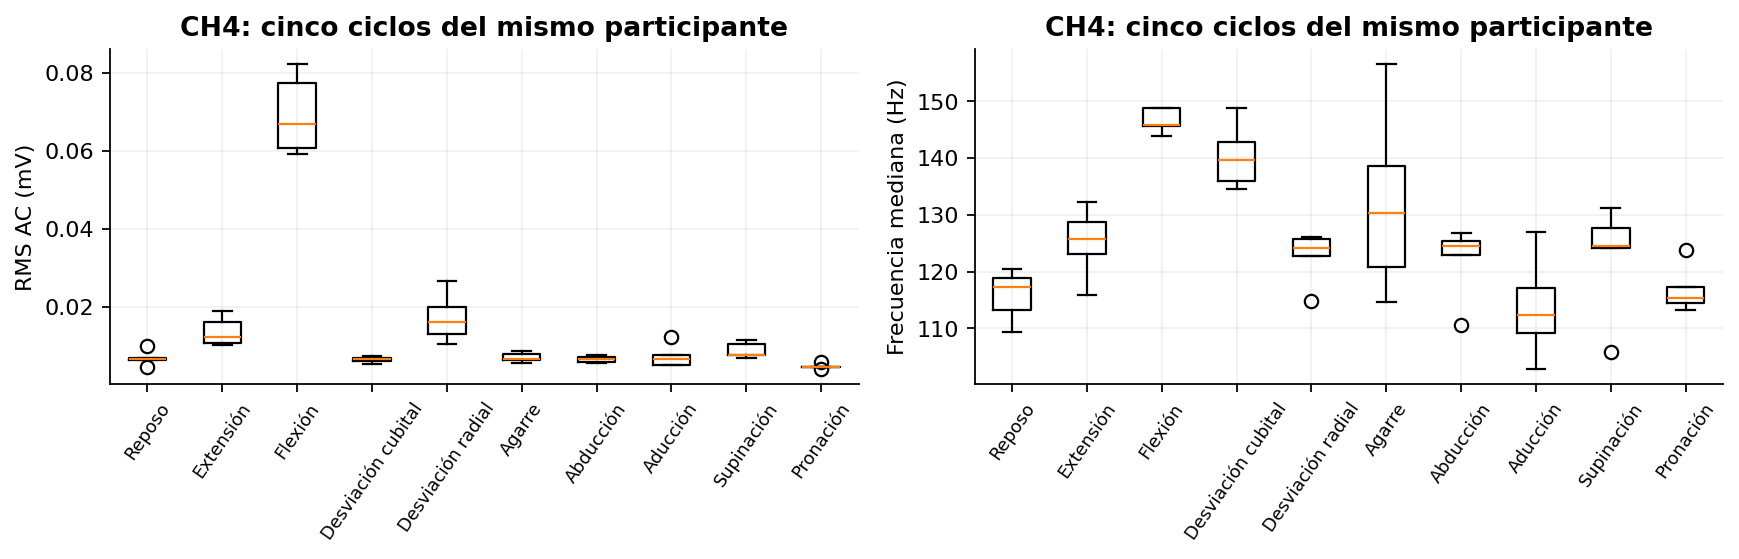

In [2]:
ventanas,protocolo=characteristics(ROOT)
display(ventanas.head())
display(ventanas[~ventanas.valida_calidad])
display(pd.read_csv(ROOT/'evidencias/comparacion_reposo_agarre.csv'))
display(Image(filename=str(ROOT/'figuras/comparacion_reposo_agarre_psd.png')))
display(Image(filename=str(ROOT/'figuras/caracteristicas_gestos.png')))


## Etiquetas y comparación real
El script original `EMG_gesture_segmentation.m` fija los inicios de ciclo en 4, 138, 272, 406 y 540 s. En cada ciclo hay diez tareas de 6 s separadas por 4 s. Se traduce MATLAB `[a*fs+1:b*fs]` a Python `[a*fs:b*fs]`. Se usa la ventana central de 2 s de cada tarea, desde inicio+2 hasta inicio+4, para reducir exposición a transiciones. Resultado: 50 tareas y 200 filas canal-tarea. Las etiquetas son tareas programadas, sin confirmación cinemática independiente.

La comparación a priori del canal 4 usa reposo [6; 8) s y agarre [56; 58) s del primer ciclo. Sus RMS son muy parecidos (0,006439 y 0,006524 mV): este contraste no acredita separación útil entre ambas tareas. En los cinco ciclos, la flexión nominal tiene una mediana RMS mayor (0,066918 mV) que el reposo (0,006439 mV). Se describe solo este participante/canal; los cinco ciclos no son cinco participantes y no se infiere desempeño de clasificación.

## Operación temporal y validación separada
Se compara el CH4 centrado globalmente con una reducción 2.000 a 1.000 Hz mediante `resample_poly(up=1, down=2)`. El FIR antialias tiene 161 coeficientes, corte de diseño 450 Hz, ventana Kaiser beta=8,6 y extensión lineal. Conserva aproximadamente la banda hasta 400 Hz y atenúa contenido cercano al límite de salida de 500 Hz y superior. Se declara esa pérdida. Las características principales se calculan en la señal a 2.000 Hz, sin sustituirla por la reducida. La mera selección de una de cada dos filas se incluye solo como contraste.

La FFT sintética usa una sinusoide de 50 Hz, amplitud 1 mV, fs=2.000 Hz, N=4.000, Hann periódica y amplitud unilateral corregida por ganancia coherente (DC y Nyquist sin duplicar). Debe recuperar 50 Hz dentro de 0,5 Hz, y amplitud cercana a 1 mV. Otra prueba sintética muestra el alias de 700 a 300 Hz al reducir sin filtro y comprueba la atenuación con FIR. Ambas pruebas verifican mecanismos del código, sin representar actividad muscular real.

                                      version  muestras  fs_Hz  duracion_s  desv_mV
                        Original CH4 centrado   1280000 2000.0       640.0 0.018601
                  Remuestreo FIR antialias x2    640000 1000.0       640.0 0.018573
Selección cada 2 filas sin filtro (contraste)    640000 1000.0       640.0 0.018602
{
  "canal": "Canal_4",
  "metodo": "resample_poly up=1 down=2; FIR explícito",
  "numtaps": 161,
  "fir_cutoff_Hz": 450,
  "window": "Kaiser beta=8.6",
  "padtype": "line",
  "banda_aprox_conservada_Hz": [
    0,
    400
  ],
  "nyquist_salida_Hz": 500,
  "atenuacion_maxima_banda_stop_desde_500_dB": -89.51188400095909,
  "fraccion_potencia_entrada_500_1000_Hz": 0.0012231403979544358,
  "limitacion": "Reduce contenido cercano a 450 Hz y superior. No se usa para las características principales. Bordes afectados por extensión y FIR."
}
{
  "tipo": "SINTÉTICA: verificación de código, separada de los datos reales",
  "fs_Hz": 2000,
  "N": 4000,
  "duracion_s":

,version,muestras,fs_Hz,duracion_s,desv_mV
0,Original CH4 centrado,1280000,2000.0,640.0,0.018601
1,Remuestreo FIR antialias x2,640000,1000.0,640.0,0.018573
2,Selección cada 2 filas sin filtro (contraste),640000,1000.0,640.0,0.018602


{
  "tipo": "SINTÉTICA: verificación de código, separada de los datos reales",
  "fs_Hz": 2000,
  "N": 4000,
  "duracion_s": 2.0,
  "f_conocida_Hz": 50.0,
  "f_fft_Hz": 50.0,
  "error_Hz": 0.0,
  "amplitud_entrada_mV": 1,
  "amplitud_fft_mV": 0.9999999999999996,
  "delta_f_Hz": 0.5,
  "ventana": "Hann periódica; amplitud unilateral corregida por suma de ventana, DC y Nyquist sin duplicar",
  "prueba_alias_entrada_Hz": 700,
  "alias_sin_filtro_Hz": 300.0,
  "atenuacion_tono_700_dB": -104.71459284532185,
  "pruebas_superadas": true
}


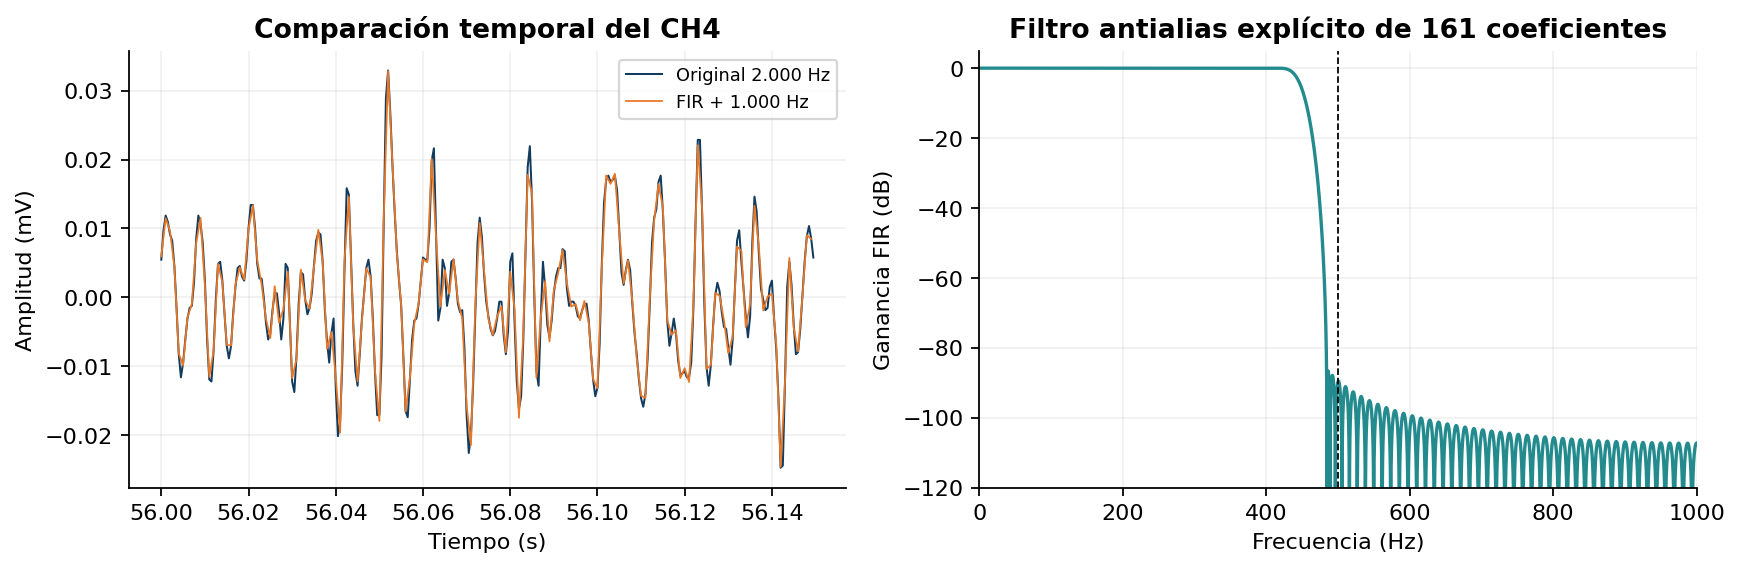

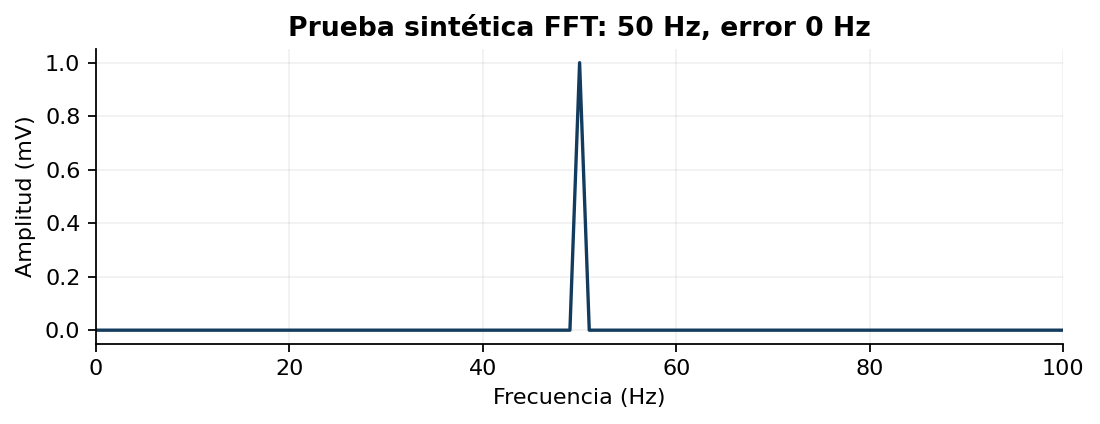

{
  "python": "3.10.7",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "scipy": "1.15.3",
  "matplotlib": "3.10.8",
  "ventana_s": 2,
  "solapamiento_ventanas_s": 0,
  "welch_nperseg": 2000,
  "welch_noverlap": 1000,
  "welch_window": "hann periódica",
  "welch_detrend": "constant por subsegmento",
  "welch_scaling": "density unilateral",
  "dominio_Hz": [
    0,
    1000
  ],
  "paso_frecuencias_welch_Hz": 1,
  "integracion": "trapecios; mediana interpolada en potencia acumulada",
  "filas_ventanas": 1280,
  "filas_ventanas_validas": 1277,
  "filas_protocolo": 200,
  "filas_protocolo_validas": 200,
  "nota": "RMS y MAV de señal centrada por ventana. No equivalen a fuerza. Etiquetas describen protocolo nominal."
}


In [3]:
comparacion,validacion=temporal_and_validation(ROOT)
display(comparacion)
print(json.dumps(validacion,ensure_ascii=False,indent=2))
display(Image(filename=str(ROOT/'figuras/comparacion_decimacion.png')))
display(Image(filename=str(ROOT/'figuras/validacion_fft_sintetica.png')))
print((ROOT/'evidencias/parametros_analisis.json').read_text(encoding='utf-8'))


## Límites, reproducción y uso de IA
Las diferencias de amplitud no se traducen en newtons. No se ha entrenado un clasificador ni evaluado generalización a otros participantes. El tiempo se sustenta en metadatos, las tareas en el protocolo y el mapa anatómico individual no se verificó. La máscara es conservadora y no detecta todo artefacto posible. La reducción de tasa pierde banda y modifica bordes. Los resultados no validan la matriz tactosensible.

Se utilizó Codex/ChatGPT para proponer y revisar código, organizar evidencia y redactar documentos. Se adoptaron el cotejo completo del original, las banderas y la integración de PSD; se descartaron causas de hardware no demostradas y la interpretación de RMS=0 como reposo. La ejecución desde kernels nuevos y las pruebas sintéticas quedan documentadas. El estudiante debe revisar las decisiones y poder explicarlas.

Fuentes: [dataset v2](https://data.mendeley.com/datasets/ckwc76xr2z/2), [artículo](https://doi.org/10.1016/j.dib.2022.107921), [Welch en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.welch.html), [resample_poly](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html), [rfft en NumPy](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html).